# m6A switches along condensate-associated lncRNAs: which RBPs prefer switch-linked elements?

**Visualization only.** Results are produced by `scripts/m6a_switch/lncrna_m6a_switch_clip.py` (pipeline steps `lncrna_*`) and read from `OUT`:
```
python scripts/m6a_switch/lncrna_m6a_switch_clip.py --prepare  # fold every RMBase m6A site, build element catalogs
# SLURM array over the 338 CLIP datasets (40 chunks), then:
python scripts/m6a_switch/lncrna_m6a_switch_clip.py --merge
```

- **lncRNAs:** NEAT1_2 (paraspeckles), MALAT1 (speckles), NORAD (NP bodies), XIST (Xi territory), TUG1.
  Not tested: SLERT, SPA1/SPA2 and PNCTR (not GENCODE genes); the repeat-derived HSATIII, rDNA IGS lncRNAs and
  TERRA (satellite / rDNA / telomeric repeats are not resolvable in GRCh38, and eCLIP keeps only uniquely mapped
  reads); MIAT and FIRRE (essentially no CLIP coverage in the available cell lines).
- **Sequence:** each gene's Ensembl-canonical transcript in GENCODE v44 as **mature RNA** (exons joined; for the
  single-exon NEAT1_2 = NEAT1-202, MALAT1 and NORAD this is the genomic sequence; XIST and TUG1 are spliced).
- **m6A sites:** every RMBase site on an exonic A of that transcript.
- **Folding:** one 201-nt window centred on each site in transcript coordinates (cut at the transcript ends; can
  span exon junctions), base pairs <= 150 nt apart (Lange et al. 2012 W = 200 / L = 150), ViennaRNA partition
  function.
- **Calls:** p(i,j) >= 0.5 to the most probable partner U, which is in a run of >= 3 U's (**U-rich**) or in a
  UGU/UUG/GUG/GUU 3-mer (**UG-rich**).
- **CLIP test (all 338 datasets):** every U-tract (>= 3 U) / every UG 3-mer along the transcript; "switch" elements
  contain the partner U of a competent site, "other" = all the rest (elements spanning an exon junction are counted
  on both genomic pieces). For each dataset: fraction of its **crosslinked positions** on that element type that
  fall in switch elements, vs. the switch share of the element type (`expected`); one-sided binomial test, BH q
  within gene x element over the **tested** datasets only: a dataset is tested on a gene x element type when it has
  >= 20 crosslinked positions in that element type (otherwise lowly covered lncRNAs give 'significant' calls from
  2-3 crosslinks). Same test as the 3'UTR analysis. Read counts are deliberately not used: the CLIP data come
  from other cell lines, so only the presence of crosslink evidence at a position is informative, not its abundance.

In [1]:
import json
import os

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

from utrals.paths import PROJECT_DIR  # data locations outside the repository (paths.env)
OUT = f"{PROJECT_DIR}/MN_diff/results/RNA_modifs/m6A/lncRNA_switch"
figures_subfolder = "../Figures/Figure_m6A/m6A_switches_lncRNAs"
os.makedirs(figures_subfolder, exist_ok=True)

# save_figure saves a figure and lists it, with its legend, in ../Figures/README.md
from functools import partial
from utrals import figures
save_figure = partial(figures.save_figure, notebook="Figure_m6A_lncRNA_switch.ipynb")
figures.fix_random_seeds(0)  # fixed jitter and bootstrap confidence intervals: identical figures on every run

genes = pd.read_csv(f"{OUT}/genes.csv")["gene"].tolist()   # order as analysed
elements = ["U-tracts", "GU motifs"]
P_FLOOR = 1e-300


def stars(p):
    return "***" if p < 1e-4 else "**" if p < 1e-2 else "*" if p < 0.05 else "ns"


with open(f"{OUT}/params.json") as f:
    p = json.load(f)
print(f"produced {p['timestamp']}, git {p['git_commit'][:8]} (scripts dirty: {p['git_scripts_dirty']})")
print(json.dumps(p["run"]))

produced 2026-10-06T14:31:41, git 50106d6a (scripts dirty: True)
{"step": "lncrna_m6a_switch_clip", "genes": ["NEAT1", "MALAT1", "NORAD", "XIST", "TUG1"], "sequence": "Ensembl-canonical transcript, mature (exons joined)", "flank": 100, "max_bp_span": 150, "p_threshold": 0.5, "u_tract_min": 3, "motifs": ["UGU", "UUG", "GUG", "GUU"], "n_chunks": 40, "test": "crosslinked positions, one-sided binomial", "min_crosslinks_tested": 20}


## 1. m6A sites and switch-competent sites per gene

In [2]:
genes_df = pd.read_csv(f"{OUT}/genes.csv").set_index("gene").loc[genes]
genes_df

,transcript_id,transcript_name,chrom,start,end,strand,n_exons,length,n_rmbase_sites,n_sites_on_A,n_u_rich,n_ug_rich,n_u_tracts,n_switch_u_tracts,n_motifs,n_switch_motifs
gene,,,,,,,,,,,,,,,,
NEAT1,ENST00000501122.2,NEAT1-202,chr11,65422797,65445540,+,1,22743,230,230,27,62,584,26,2244,91
MALAT1,ENST00000534336.3,MALAT1-202,chr11,65497639,65508073,+,1,10434,134,134,13,26,267,13,820,38
NORAD,ENST00000565493.2,NORAD-201,chr20,36045617,36051018,-,1,5401,105,105,7,29,131,6,548,47
XIST,ENST00000429829.6,XIST-204,chrX,73820655,73852723,-,6,19245,171,171,3,27,509,2,1604,37
TUG1,ENST00000644773.3,TUG1-217,chr22,30969264,30979395,+,3,7474,187,187,23,50,172,21,559,71


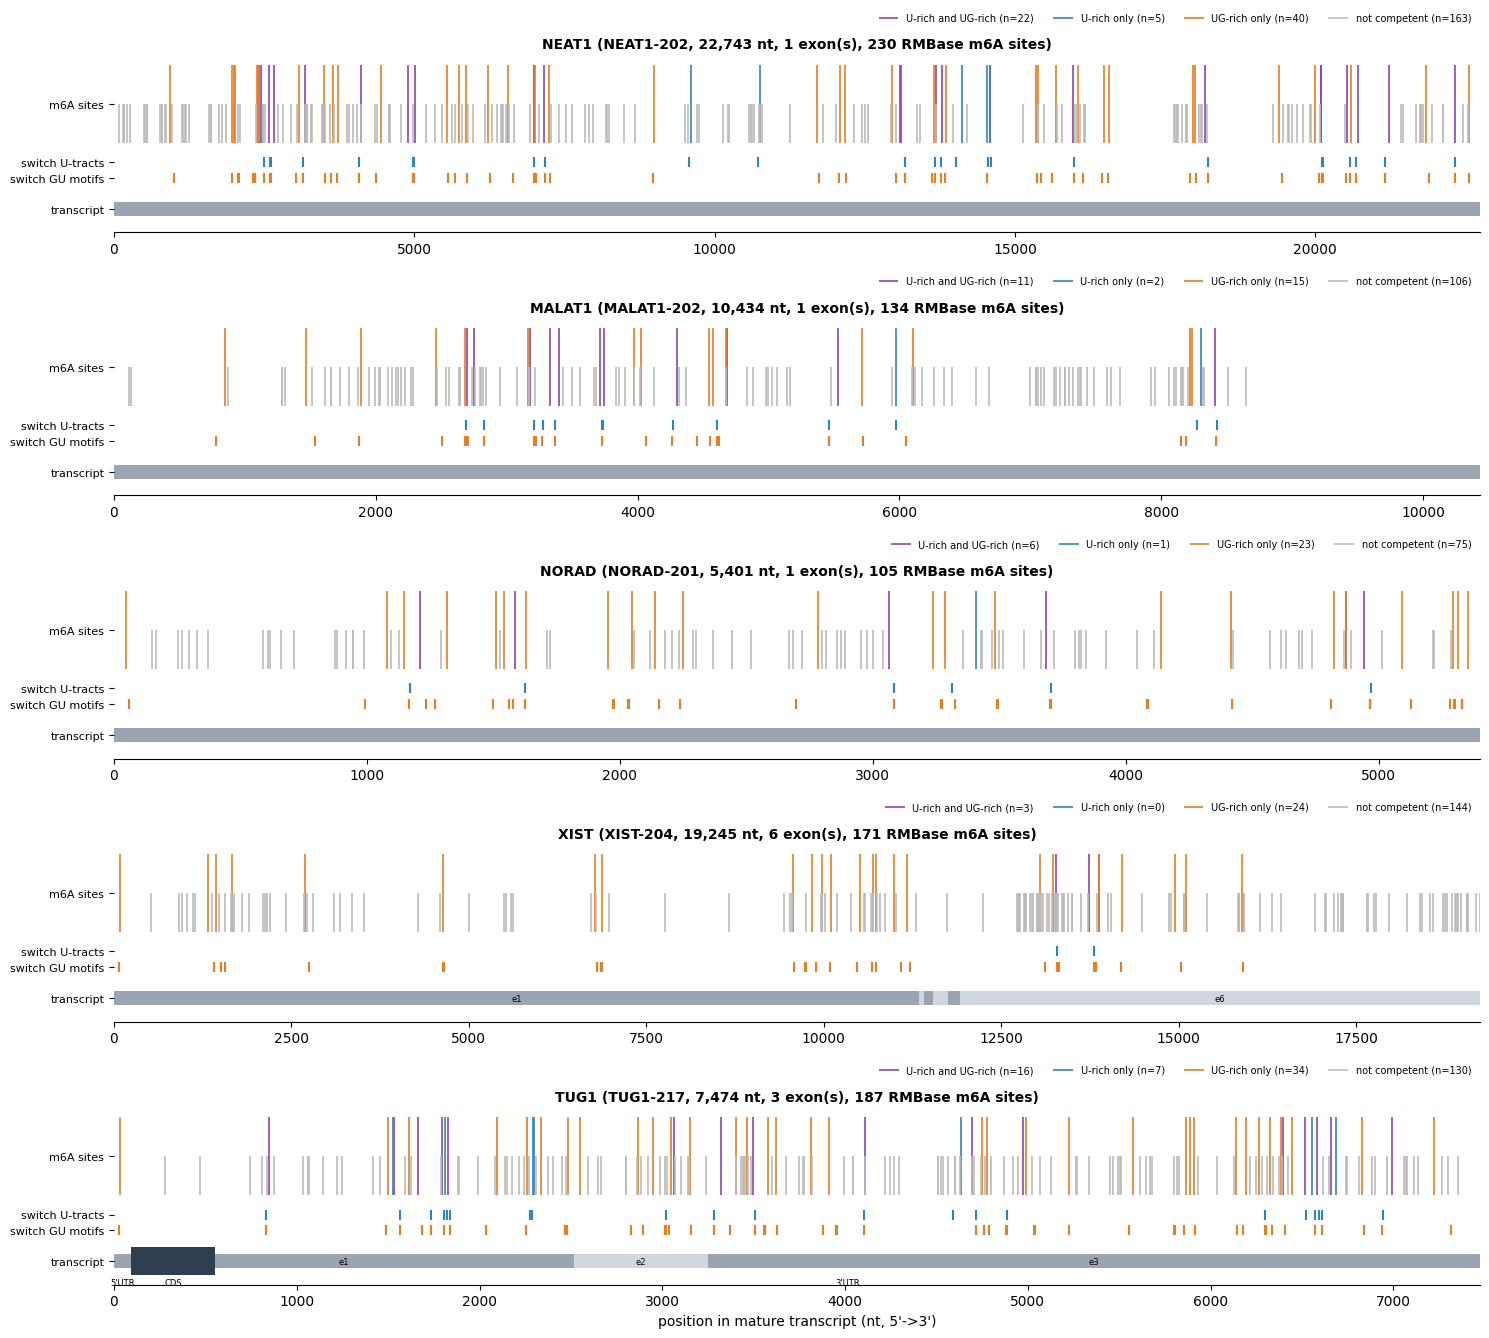

In [3]:
sites = pd.read_csv(f"{OUT}/per_site.csv")
u_cat = pd.read_csv(f"{OUT}/u_tract_catalog.csv")
gu_cat = pd.read_csv(f"{OUT}/motif_catalog.csv")
features = pd.read_csv(f"{OUT}/transcript_features.csv")   # exons / CDS / UTRs in transcript coordinates
call_colors = {"U-rich and UG-rich": "#8e44ad", "U-rich only": "#2e86c1", "UG-rich only": "#e67e22", "not competent": "#bbbbbb"}
sites["call"] = np.select([sites["u_rich"] & sites["ug_rich"], sites["u_rich"], sites["ug_rich"]],
                          ["U-rich and UG-rich", "U-rich only", "UG-rich only"], "not competent")


def draw_gene_track(ax, gene, y=-0.85, h=0.18):
    """Exons as alternating grey blocks (numbered if > 1); if annotated, CDS as a taller dark block and UTRs labelled."""
    f = features[features["gene"] == gene]
    ex = f[f["feature"] == "exon"]
    for k, r in enumerate(ex.itertuples()):
        ax.add_patch(plt.Rectangle((r.tx_start - 1, y - h / 2), r.tx_end - r.tx_start + 1, h,
                                   color=["#9aa5b1", "#cfd6dd"][k % 2], lw=0))
        if len(ex) > 1 and (r.tx_end - r.tx_start) > 0.02 * ex["tx_end"].max():
            ax.text((r.tx_start + r.tx_end) / 2, y, f"e{int(r.number)}", ha="center", va="center", fontsize=6)
    for r in f[f["feature"] == "CDS"].itertuples():
        ax.add_patch(plt.Rectangle((r.tx_start - 1, y - h), r.tx_end - r.tx_start + 1, 2 * h, color="#2d3e50", lw=0))
        ax.text((r.tx_start + r.tx_end) / 2, y - h - 0.03, "CDS", ha="center", va="top", fontsize=6)
    for utr in ("5'UTR", "3'UTR"):
        u = f[f["feature"] == utr]
        if len(u):
            ax.text((u["tx_start"].min() + u["tx_end"].max()) / 2, y - h - 0.03, utr, ha="center", va="top", fontsize=6)


fig, axes = plt.subplots(len(genes), 1, figsize=(15, 2.7 * len(genes)))
for ax, gene in zip(axes, genes):
    g = genes_df.loc[gene]
    s = sites[sites["gene"] == gene]
    for call, color in call_colors.items():
        d = s[s["call"] == call]
        h = 1.0 if call != "not competent" else 0.5
        ax.vlines(d["pos_in_gene"], 0, h, color=color, lw=1.2, label=f"{call} (n={len(d)})")
    for cat, y, color in [(u_cat, -0.25, "#2e86c1"), (gu_cat, -0.45, "#e67e22")]:
        c = cat[(cat["gene"] == gene) & (cat["category"] == "switch")].drop_duplicates("element_id")
        ax.scatter(c["tx_start"] + 1, np.full(len(c), y), marker="|", s=60, color=color)   # transcript coordinates
    draw_gene_track(ax, gene)
    ax.set_yticks([-0.85, -0.45, -0.25, 0.5])
    ax.set_yticklabels(["transcript", "switch GU motifs", "switch U-tracts", "m6A sites"], fontsize=8)
    ax.set_xlim(0, g["length"])
    ax.set_ylim(-1.15, 1.1)
    ax.set_title(f"{gene} ({g['transcript_name']}, {g['length']:,} nt, {g['n_exons']} exon(s), "
                 f"{len(s)} RMBase m6A sites)", weight="bold", fontsize=10)
    ax.legend(fontsize=7, loc="upper right", ncol=4, frameon=False, bbox_to_anchor=(1, 1.3))
    sns.despine(ax=ax, left=True)
axes[-1].set_xlabel("position in mature transcript (nt, 5'->3')")
plt.tight_layout()
# plt.savefig(f"{figures_subfolder}/m6a_switch_sites_along_genes.pdf", bbox_inches="tight")
plt.show()

### Positive control: the published MALAT1 m6A switch (Liu et al. 2015, HNRNPC)

The published switch is an m6A (GGACU) in a hairpin stem facing a U5-tract. The RMBase site at chr11:65,500,337
has exactly this signature (GGACU, paired with the UUUUU tract 12 nt upstream) and is called U-rich competent.
The paper's nucleotide numbering (A2577) does not map 1:1 onto the GENCODE transcripts, so the identification
rests on the sequence/structure signature (check against the hairpin sequence in the paper's figure).

In [4]:
sites[(sites["gene"] == "MALAT1") & sites["pos"].between(65500250, 65500400)][
    ["site_id", "pos", "pos_in_gene", "p_ij", "j_genomic", "u_rich", "ug_rich", "ug_motifs"]]

,site_id,pos,pos_in_gene,p_ij,j_genomic,u_rich,ug_rich,ug_motifs
262,m6A_site_147974,65500275,2637,0.987901,65500291,False,False,NaN
263,m6A_site_147975,65500284,2646,0.000138,65500291,False,False,NaN
264,m6A_site_147976,65500317,2679,0.851007,65500345,False,True,GUU
265,m6A_site_147977,65500337,2699,0.842223,65500325,True,True,"GUU,UGU"
266,m6A_site_147978,65500371,2733,0.001487,65500363,False,False,NaN
267,m6A_site_147979,65500385,2747,0.538916,65500465,True,True,"GUU,UGU"
268,m6A_site_147980,65500392,2754,0.058285,65500399,False,False,NaN


## 2. CLIP: all 338 datasets, per gene x element

In [5]:
clip_all = pd.read_csv(f"{OUT}/clip_enrichment_all_datasets.csv")   # every dataset, incl. untested
clip = clip_all[clip_all["tested"]]   # datasets with >= 20 crosslinked positions in the element type
rbp = pd.read_csv(f"{OUT}/rbp_summary.csv")
overview = (clip_all.assign(sig=clip_all["q_value_bh"] < 0.05)
            .groupby(["gene", "element"], sort=False)
            .agg(expected_rate=("expected_rate", "first"), n_datasets=("dataset", "size"),
                 n_with_crosslinks=("n_crosslinks_in_elements", lambda n: int((n > 0).sum())),
                 n_tested=("tested", "sum"), n_significant_q05=("sig", "sum"),
                 median_fc_tested=("fold_change", lambda x: x[clip_all.loc[x.index, "tested"]].median()))
            .reindex([(g, e) for g in genes for e in elements]))
clip_genes = [g for g in genes if (clip["gene"] == g).any()]   # lncRNAs with >= 1 tested dataset
print("no tested dataset (not shown in the CLIP plots):", [g for g in genes if g not in clip_genes])
overview

no tested dataset (not shown in the CLIP plots): []


expected_rate  n_datasets  n_with_crosslinks  n_tested  \
gene   element                                                             
NEAT1  U-tracts        0.041938         338                337       336   
       GU motifs       0.040553         338                338       337   
MALAT1 U-tracts        0.052838         338                337       337   
       GU motifs       0.046341         338                338       337   
NORAD  U-tracts        0.044872         338                335       236   
       GU motifs       0.085766         338                336       297   
XIST   U-tracts        0.003284         338                222       183   
       GU motifs       0.023067         338                217       184   
TUG1   U-tracts        0.125589         338                337       209   
       GU motifs       0.127013         338                335       254   

                  n_significant_q05  median_fc_tested  
gene   element                                         
NEAT1  U-tracts                   0          1.105622  
       GU motifs                 51          1.130668  
MALAT1 U-tracts                   0          1.342929  
       GU motifs                298          1.418423  
NORAD  U-tracts                   0          0.768473  
       GU motifs                  0          0.915673  
XIST   U-tracts                   0          0.000000  
       GU motifs                  1          0.807163  
TUG1   U-tracts                   0          0.736029  
       GU motifs                  0          0.691394

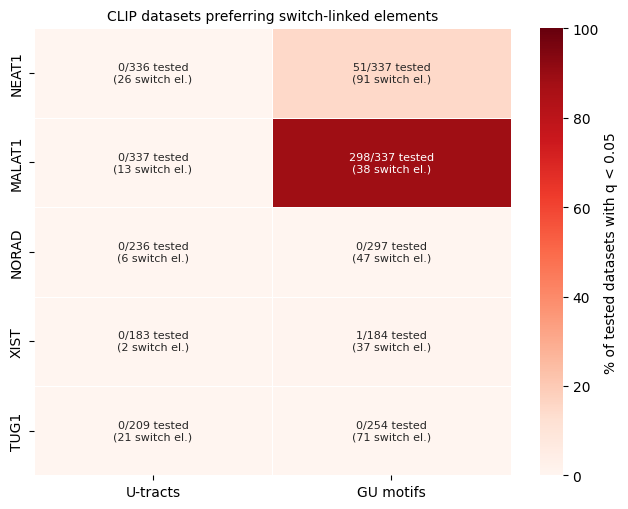

In [6]:
# Summary across lncRNAs: % of the TESTED datasets (>= 20 crosslinked positions) with q < 0.05 (colour), annotated
# with significant / tested and with how many switch-linked elements the test rests on (few = little power).
n_switch = pd.concat([u_cat.assign(element="U-tracts"), gu_cat.assign(element="GU motifs")])
n_switch = (n_switch[n_switch["category"] == "switch"].groupby(["gene", "element"])["element_id"].nunique())
summ = overview.reset_index()
summ["pct_sig"] = 100 * summ["n_significant_q05"] / summ["n_tested"].replace(0, np.nan)
summ["label"] = [(f"{int(r.n_significant_q05)}/{int(r.n_tested)} tested" if r.n_tested else "not testable\n(no coverage)")
                 + f"\n({int(n_switch.get((r.gene, r.element), 0))} switch el.)" for r in summ.itertuples()]
heat = summ.pivot(index="gene", columns="element", values="pct_sig").reindex(index=genes, columns=elements)
annot = summ.pivot(index="gene", columns="element", values="label").reindex(index=genes, columns=elements)
fig, ax = plt.subplots(figsize=(6.5, 0.8 * len(genes) + 1.2))
ax.set_facecolor("#eeeeee")   # grey = not testable
sns.heatmap(heat, annot=annot, fmt="", cmap="Reds", vmin=0, vmax=100, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "% of tested datasets with q < 0.05"}, ax=ax, annot_kws={"fontsize": 8})
for (i, g), (k, e) in [((i, g), (k, e)) for i, g in enumerate(heat.index) for k, e in enumerate(heat.columns)]:
    if np.isnan(heat.loc[g, e]):   # heatmap does not annotate empty cells
        ax.text(k + 0.5, i + 0.5, annot.loc[g, e], ha="center", va="center", fontsize=8, color="#555555")
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("CLIP datasets preferring switch-linked elements", fontsize=10)
plt.tight_layout()
# plt.savefig(f"{figures_subfolder}/summary_all_lncRNAs.pdf", bbox_inches="tight")
plt.show()

### Fold change vs. significance (all datasets), region-2 candidates coloured and labelled

y = -log10(q), the BH-corrected p-value (within gene x element, over the 338 datasets); dotted line = q = 0.05,
so every point above it is significant.

Candidates = `../Tables/Figure_regulators_lengthening/regulators_of_nuclear_3UTR_lengthening_D22_to_D35_CTRL_region2_downstream_pPAS_APA_vs_nuclear_retention_class.csv`, matched to their CLIP dataset; colour = category (APA /
nuclear retention). Black outline = q < 0.05. All other datasets in grey (darker = q < 0.05).

In [7]:
from utrals.m6a_switch.clip_enrichment_u_tract import resolve_clip_file

CANDIDATES_CSV = figures.lengthening_regulators_csv(2)   # written by Figure_regulators_lengthening.ipynb
category_palette = {"APA": "#dd54af", "Nuclear retention": "#5cb76b"}
cand = pd.read_csv(CANDIDATES_CSV, index_col=0)
datasets = pd.read_csv(f"{OUT}/datasets.csv")
dataset_of_path = dict(zip(datasets["path"], datasets["dataset"]))
cand["dataset"] = [dataset_of_path[resolve_clip_file(r)] for r in cand["regulator"]]
cand_category = dict(zip(cand["dataset"], cand["category"]))
cand_rbp = dict(zip(cand["dataset"], cand["RBP"]))
print(f"{len(cand)} candidates matched to CLIP datasets")


def label_column(ax, xs, ys, labels, colors, x_lab, fontsize=7, min_gap_frac=0.035):
    """Names in one column at x_lab, in the same vertical order as the points, spread so they don't
    overlap; a thin leader line joins each name to its point."""
    y0, y1 = ax.get_ylim()
    gap = min_gap_frac * (y1 - y0)
    order = np.argsort(ys)
    lab_y = []
    for k in order:
        lab_y.append(max(ys[k], lab_y[-1] + gap) if lab_y else ys[k])
    shift = max(0, lab_y[-1] - (y1 - gap)) if lab_y else 0      # keep the column inside the axes
    for k, ly in zip(order, lab_y):
        ax.annotate(labels[k], (xs[k], ys[k]), xytext=(x_lab, ly - shift), textcoords="data", fontsize=fontsize,
                    color=colors[k], weight="bold", va="center",
                    arrowprops=dict(arrowstyle="-", color=colors[k], lw=0.5, alpha=0.6, shrinkA=0, shrinkB=3))


def volcano(gene, scale):
    """scale = 'log2' (x = log2 FC, no preference at 0) or 'raw' (x = FC, no preference at 1)."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, element in zip(axes, elements):
        d = clip[(clip["gene"] == gene) & (clip["element"] == element) & (clip["n_crosslinks_in_elements"] > 0)].copy()
        if scale == "log2":
            with np.errstate(divide="ignore"):
                fc = np.log2(d["fold_change"])
            d["fc"] = fc.where(np.isfinite(fc), fc[np.isfinite(fc)].min() - 0.2)   # -inf (0 switch crosslinks) at the edge
        else:
            d["fc"] = d["observed_rate"] / d["expected_rate"]
        d["neg_log10_p"] = -np.log10(d["q_value_bh"].clip(lower=P_FLOOR))   # y = -log10(q)
        d["sig"] = d["q_value_bh"] < 0.05
        d["category"] = d["dataset"].map(cand_category)
        rest, c = d[d["category"].isna()], d[d["category"].notna()]
        ax.scatter(rest.loc[~rest["sig"], "fc"], rest.loc[~rest["sig"], "neg_log10_p"], s=12, color="#cccccc",
                   edgecolor="none", label=f"other datasets, n.s. (n={(~rest['sig']).sum()})")
        ax.scatter(rest.loc[rest["sig"], "fc"], rest.loc[rest["sig"], "neg_log10_p"], s=12, color="#888888",
                   edgecolor="none", label=f"other datasets, q < 0.05 (n={rest['sig'].sum()})")
        for cat, color in category_palette.items():
            cc = c[c["category"] == cat]
            ax.scatter(cc["fc"], cc["neg_log10_p"], s=60, color=color, zorder=3,
                       edgecolor=np.where(cc["sig"], "black", "none"), linewidth=1.0,
                       label=f"candidate, {cat} (n={len(cc)})")
        span = d["fc"].max() - d["fc"].min()
        x_lab = d["fc"].max() + 0.08 * span
        ax.set_xlim(d["fc"].min() - 0.05 * span, x_lab + 0.22 * span)
        ax.set_ylim(0, max(d["neg_log10_p"].max() * 1.1, -np.log10(0.05) * 1.25))   # always show the q = 0.05 line
        label_column(ax, c["fc"].values, c["neg_log10_p"].values, c["dataset"].map(cand_rbp).values,
                     c["category"].map(category_palette).values, x_lab)
        ax.axvline(0 if scale == "log2" else 1, color="grey", linestyle=":", linewidth=1)
        ax.axhline(-np.log10(0.05), color="grey", linestyle=":", linewidth=1)
        ax.set_xlabel("log2 fold change (observed / expected)" if scale == "log2" else "fold change (observed / expected)")
        ax.set_ylabel("-log10(q-value) (BH-corrected)")
        ax.set_title(f"{element}: expected fraction {d['expected_rate'].iloc[0]:.3f} "
                     f"(candidates with q < 0.05: {int(c['sig'].sum())}/{len(c)})", fontsize=10)
        ax.legend(fontsize=7, loc="upper left")
        sns.despine(ax=ax)
    fig.suptitle(f"{gene}: CLIP preference for switch-linked elements, tested datasets (>= 20 crosslinked positions) "
                 f"(outlined = q < 0.05)", weight="bold")
    plt.tight_layout()
    suffix = "_log2FC" if scale == "log2" else ""
    save_figure(f"{figures_subfolder}/scatter_CLIP_preference_switch_elements_{gene}{suffix}.pdf",
                pattern=f"scatter_CLIP_preference_switch_elements_<lncRNA>{suffix}.pdf",
                legend="One file per lncRNA with >= 1 tested CLIP dataset (NEAT1, MALAT1, NORAD, XIST, TUG1): preference "
                       "of each tested CLIP dataset (>= 20 crosslinked positions in the element type) for m6A-switch-linked "
                       "U-tracts (left) and GU motifs (right) along the mature transcript. x = fold change, observed / "
                       "expected share of crosslinked positions in switch-linked elements (dotted line = no preference"
                       + ("; log2 scale" if scale == "log2" else "") + "); y = -log10(q), one-sided binomial test, BH "
                       "within gene x element over the tested datasets. Grey = other datasets (darker = q < 0.05); R2 "
                       "regulators of lengthening coloured by class (APA pink, nuclear retention green), black outline = "
                       "q < 0.05.")
    plt.show()



17 candidates matched to CLIP datasets


Same plots with the plain fold change on the x-axis (1 = no preference, 2 = twice as often as expected).

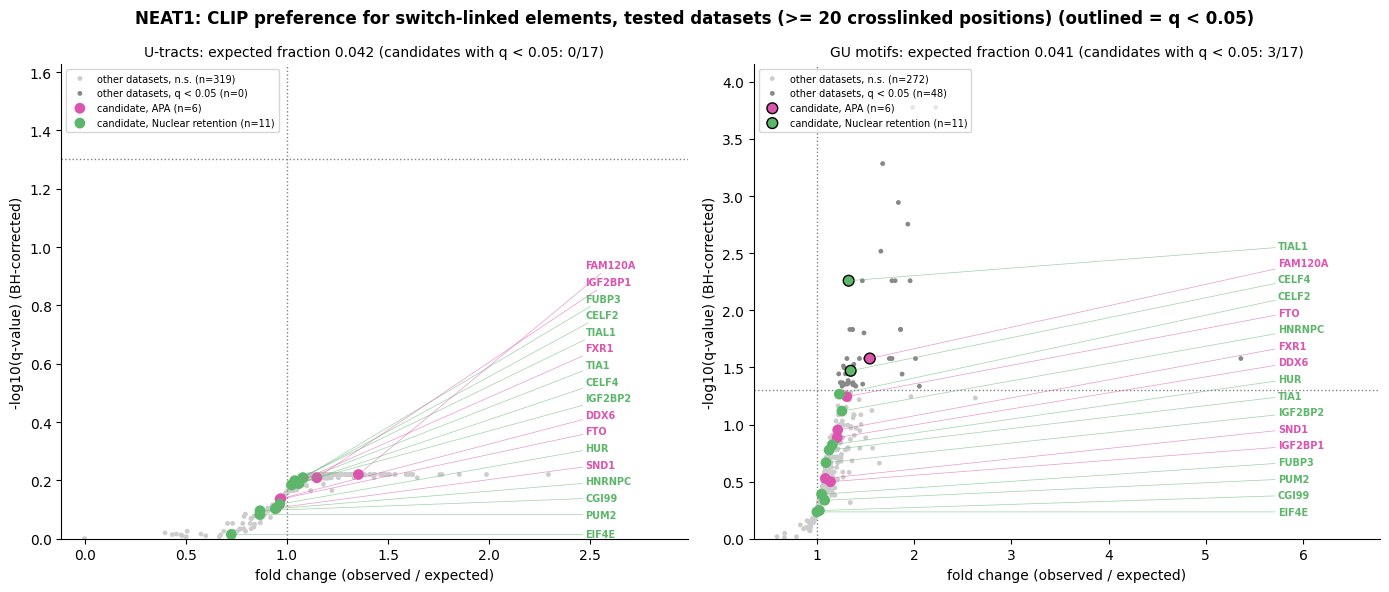

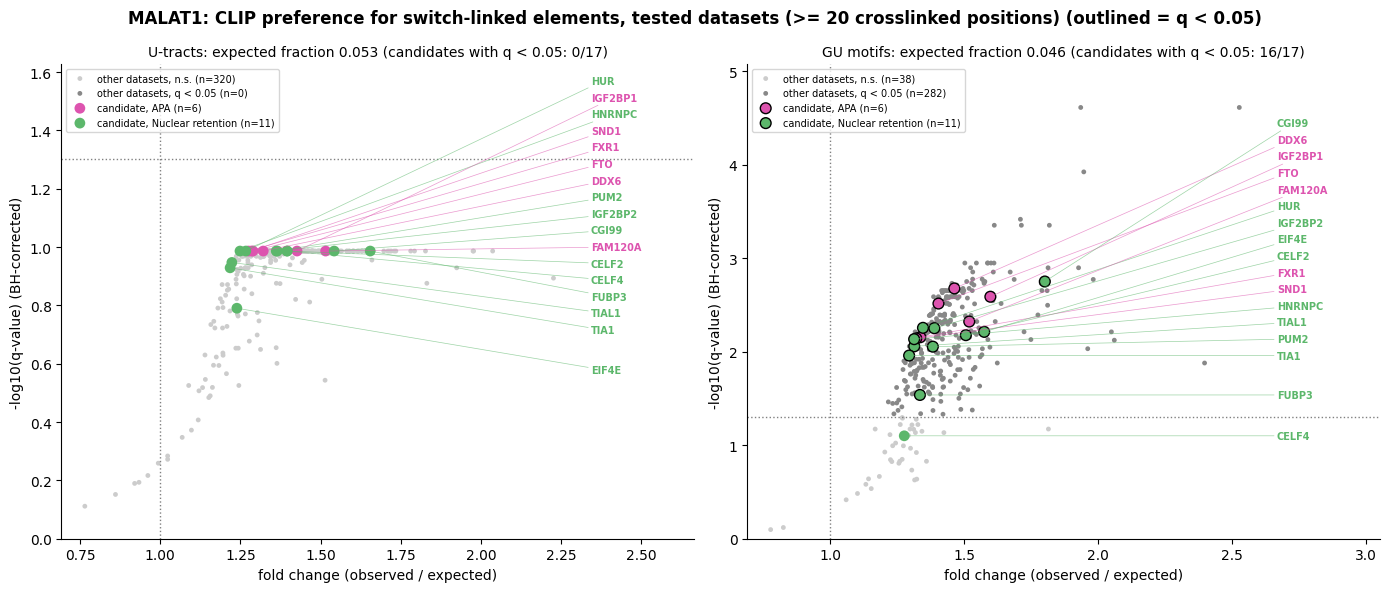

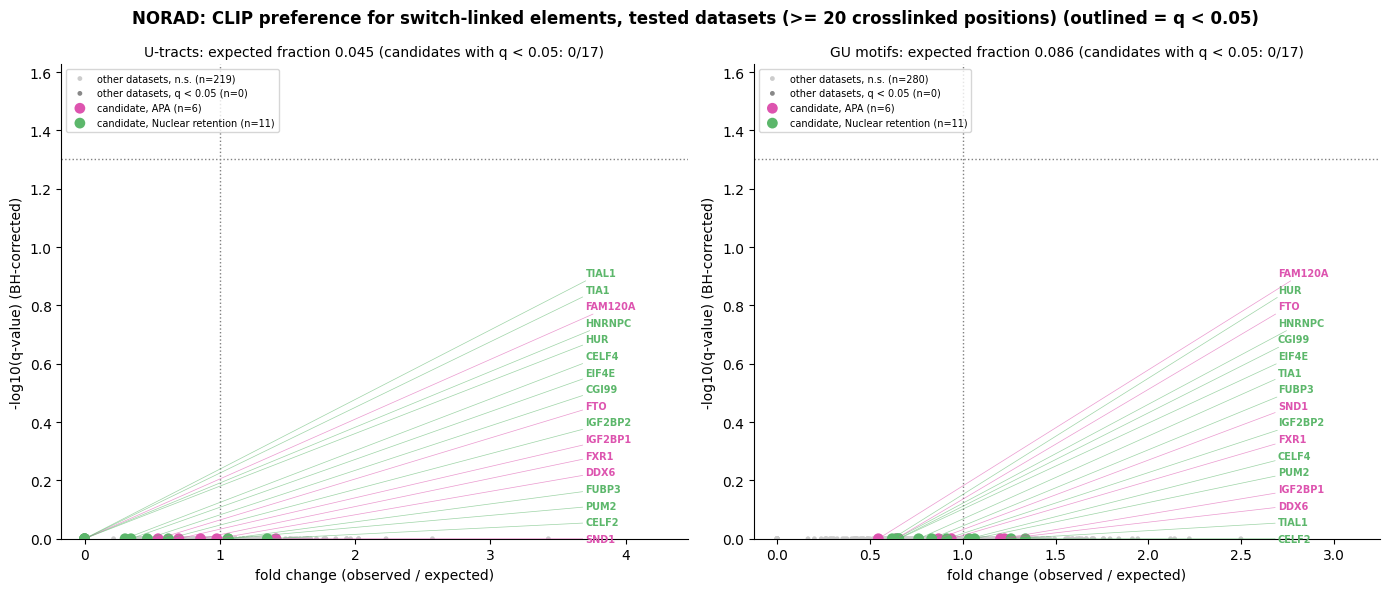

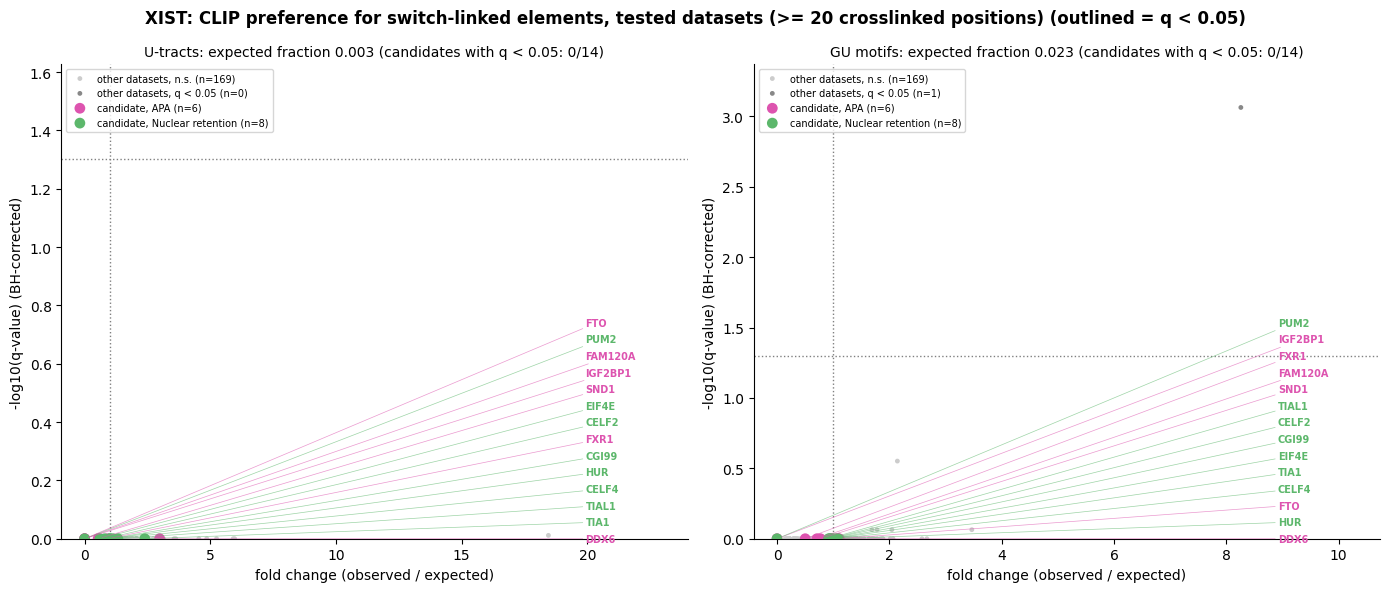

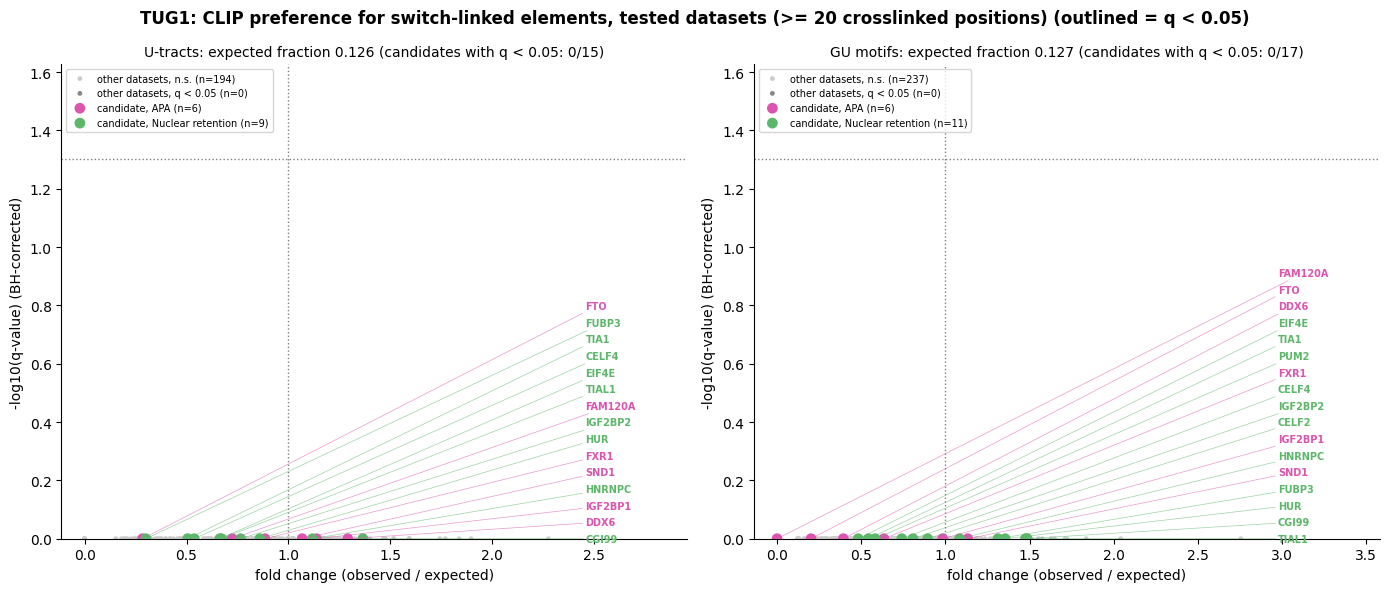

In [8]:
for gene in clip_genes:
    volcano(gene, "raw")

### RBPs with the strongest preference (top 25 by fold change)

Per RBP: its best dataset (highest FC among its significant datasets). Red = q < 0.05. When no RBP reaches
q < 0.05 (U-tracts), the panel shows the RBPs with a nominally significant dataset (p < 0.05) in grey instead --
these do not survive multiple-testing correction. Label: datasets significant (at the level shown) / all datasets.

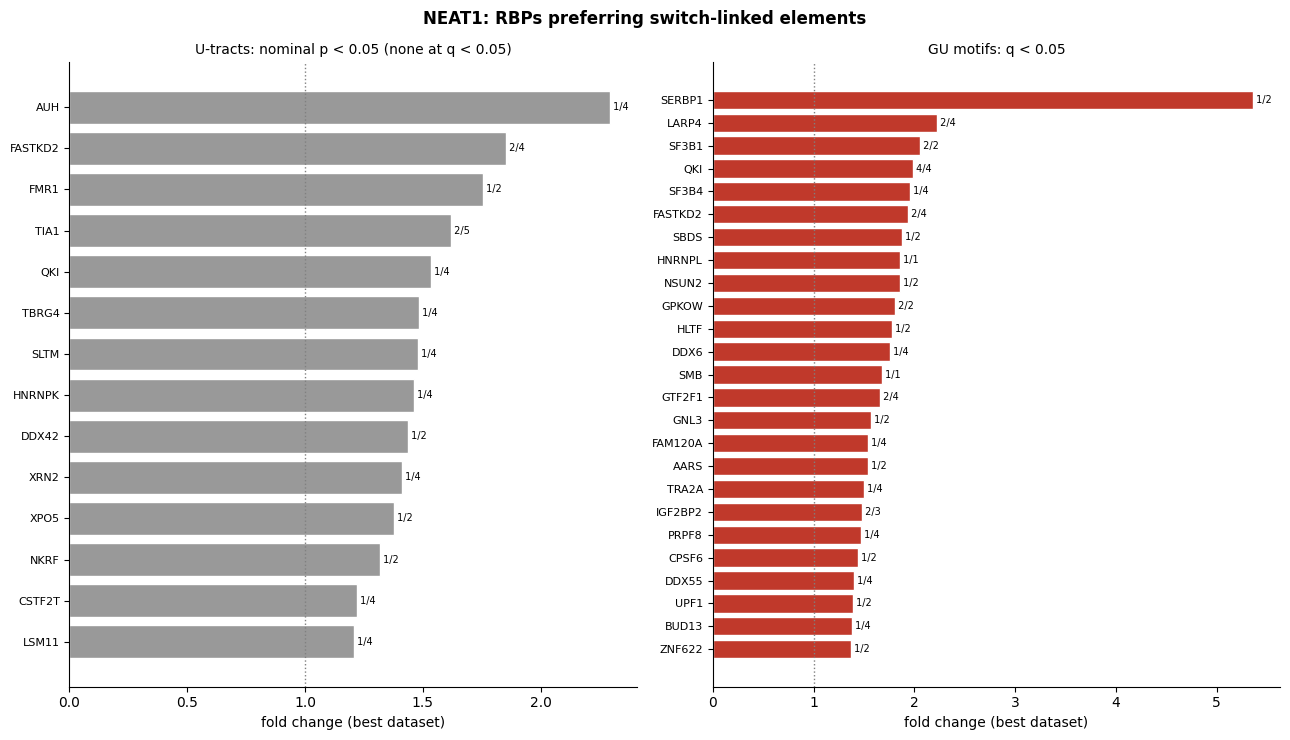

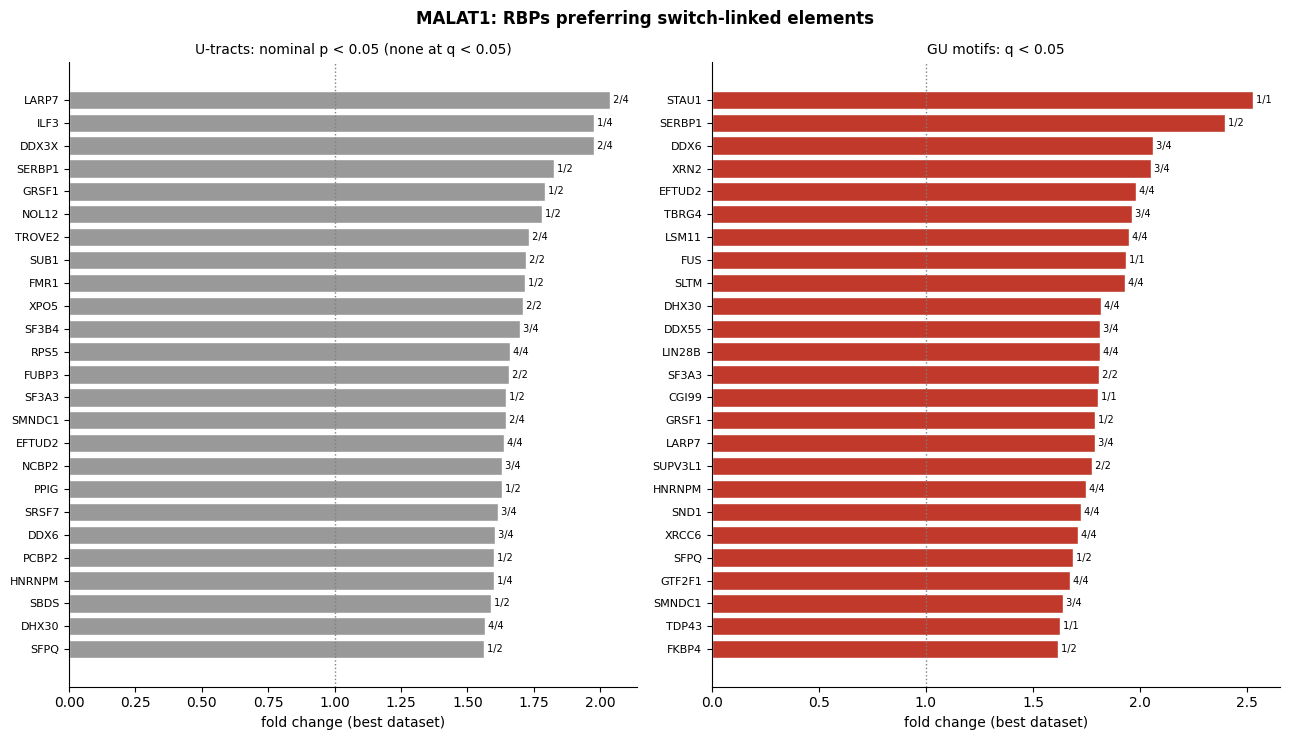

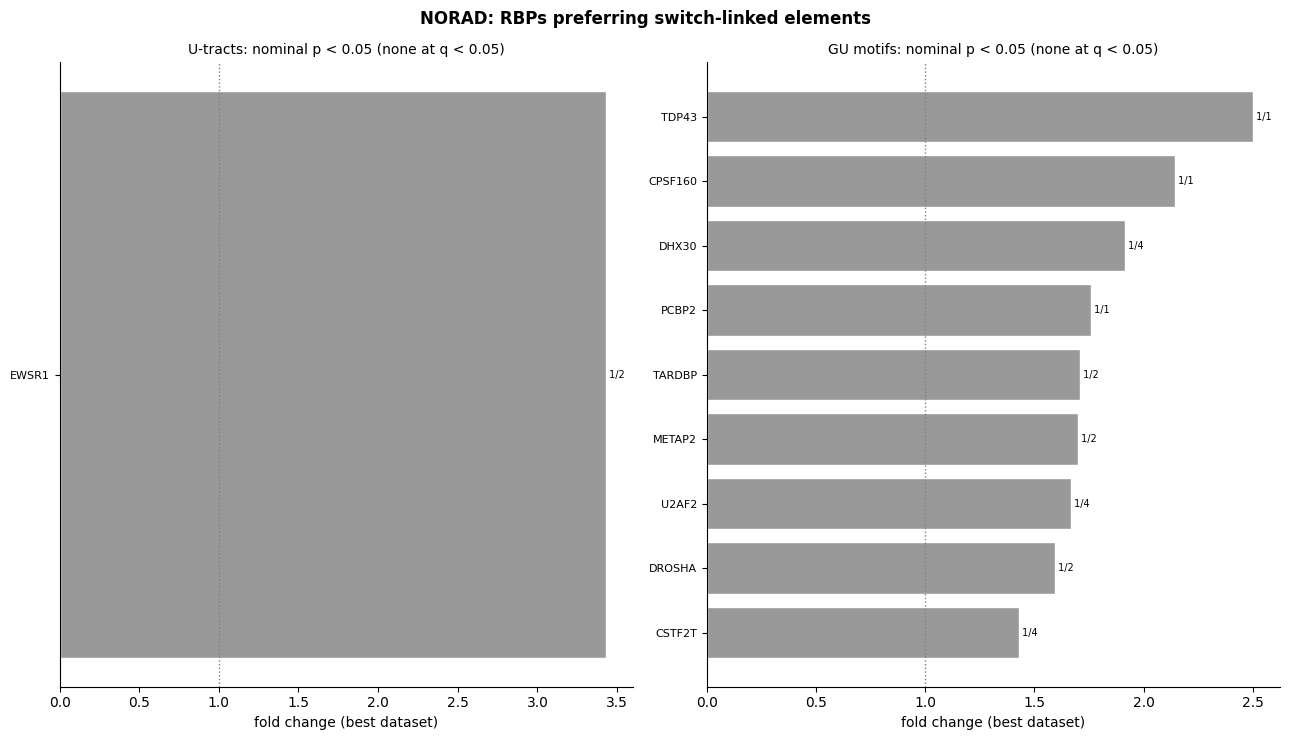

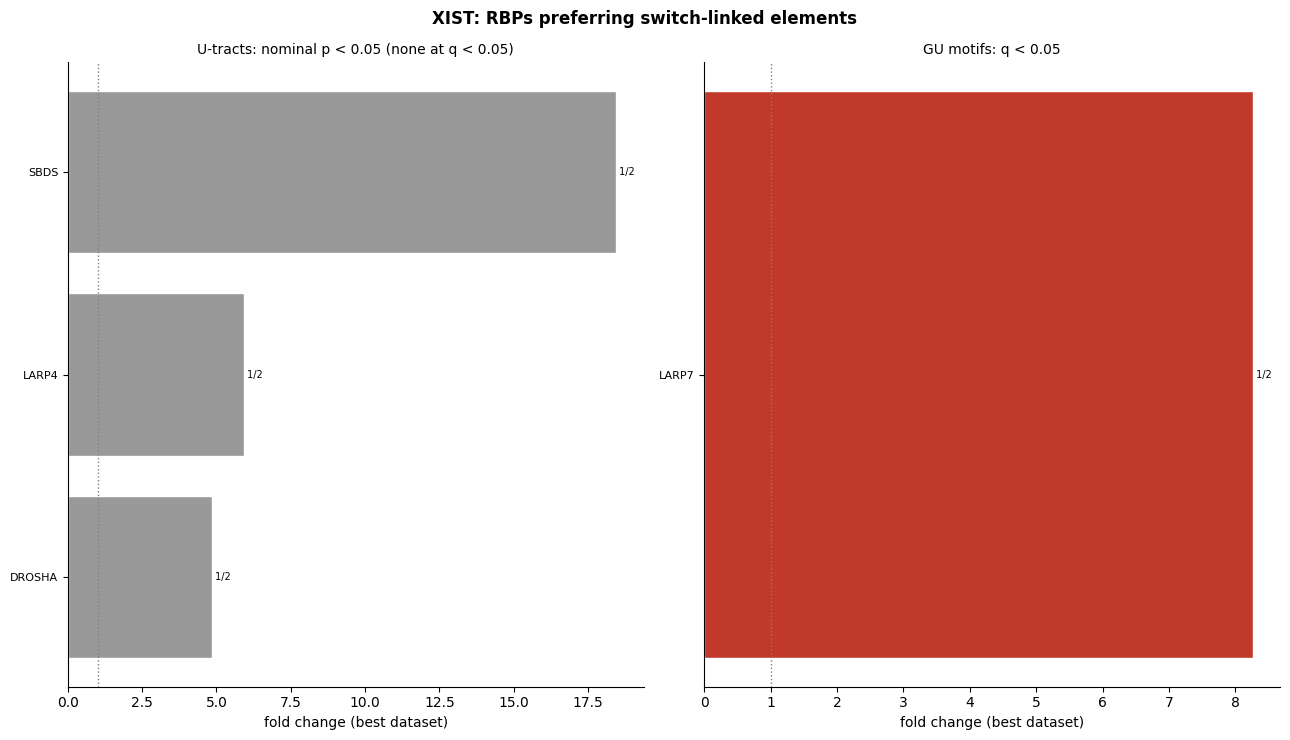

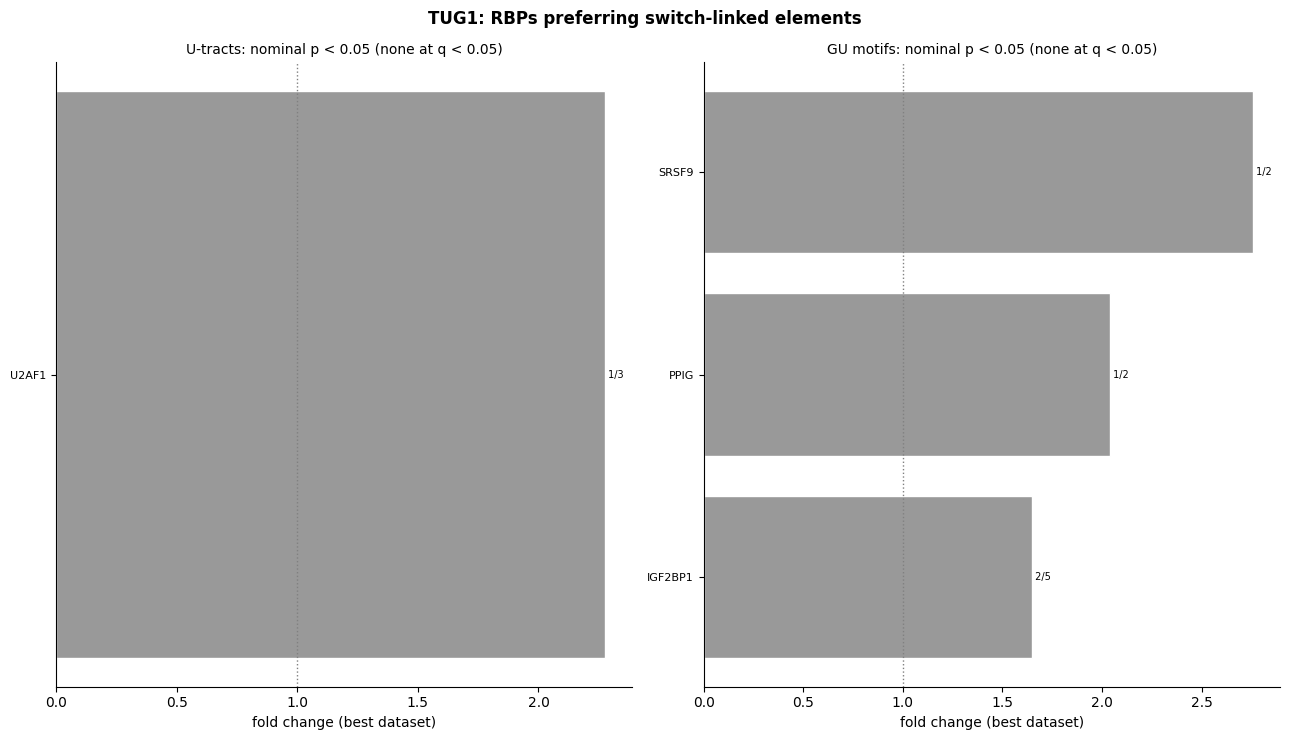

In [9]:
for gene in clip_genes:
    fig, axes = plt.subplots(1, 2, figsize=(13, 7.5))
    for ax, element in zip(axes, elements):
        r = rbp[(rbp["gene"] == gene) & (rbp["element"] == element) & (rbp["q_value_bh"] < 0.05)]
        level, color = "q < 0.05", "#c0392b"
        if r.empty:  # nothing survives BH: show nominally significant datasets, best per RBP
            d = clip[(clip["gene"] == gene) & (clip["element"] == element) & (clip["p_value"] < 0.05)]
            n_all = clip[(clip["gene"] == gene) & (clip["element"] == element)].groupby("RBP").size()
            r = (d.sort_values("fold_change", ascending=False).groupby("RBP", sort=False).first().reset_index()
                 .assign(n_datasets_significant=lambda x: x["RBP"].map(d.groupby("RBP").size()),
                         n_datasets=lambda x: x["RBP"].map(n_all)))
            level, color = "nominal p < 0.05 (none at q < 0.05)", "#999999"
        r = r.nlargest(25, "fold_change").iloc[::-1]
        ax.barh(r["RBP"], r["fold_change"], color=color, edgecolor="white")
        for k, row in enumerate(r.itertuples()):
            ax.text(row.fold_change, k, f" {row.n_datasets_significant}/{row.n_datasets}", va="center", fontsize=7)
        ax.axvline(1, color="grey", linestyle=":", linewidth=1)
        ax.set_xlabel("fold change (best dataset)")
        ax.set_title(f"{element}: {level}", fontsize=10)
        ax.tick_params(axis="y", labelsize=8)
        sns.despine(ax=ax)
    fig.suptitle(f"{gene}: RBPs preferring switch-linked elements", weight="bold")
    plt.tight_layout()
    # plt.savefig(f"{figures_subfolder}/{gene}_top_rbps.pdf", bbox_inches="tight")
    plt.show()

## 3. Full per-RBP table (significant at q < 0.05, sorted by fold change)

In [10]:
(rbp[rbp["q_value_bh"] < 0.05]
 .sort_values(["gene", "element", "fold_change"], ascending=[True, True, False])
 .set_index(["gene", "element", "RBP"]))

n_datasets  n_datasets_significant  \
gene   element   RBP                                          
MALAT1 GU motifs STAU1            1                       1   
                 SERBP1           2                       1   
                 DDX6             4                       3   
                 XRN2             4                       3   
                 EFTUD2           4                       4   
...                             ...                     ...   
NEAT1  GU motifs MTPAP            2                       2   
                 EWSR1            2                       1   
                 FUS              1                       1   
                 NONO             2                       1   
XIST   GU motifs LARP7            2                       1   

                                     best_dataset        assay  \
gene   element   RBP                                             
MALAT1 GU motifs STAU1   all-STAU1-FlpIn293_iCLIP        iCLIP   
                 SERBP1             SERBP1_2_K652   eCLIP K652   
                 DDX6                DDX6_2_HepG2  eCLIP HepG2   
                 XRN2                XRN2_2_HepG2  eCLIP HepG2   
                 EFTUD2            EFTUD2_2_HepG2  eCLIP HepG2   
...                                           ...          ...   
NEAT1  GU motifs MTPAP               MTPAP_2_K652   eCLIP K652   
                 EWSR1               EWSR1_1_K652   eCLIP K652   
                 FUS       all-FUS-GFP-Hela_iCLIP        iCLIP   
                 NONO                 NONO_2_K652   eCLIP K652   
XIST   GU motifs LARP7               LARP7_1_K652   eCLIP K652   

                         n_crosslinks_in_elements  n_in_switch_elements  \
gene   element   RBP                                                      
MALAT1 GU motifs STAU1                        333                    39   
                 SERBP1                        90                    10   
                 DDX6                         178                    17   
                 XRN2                         200                    19   
                 EFTUD2                       381                    35   
...                                           ...                   ...   
NEAT1  GU motifs MTPAP                       2186                   113   
                 EWSR1                       2690                   139   
                 FUS                         2501                   128   
                 NONO                        2939                   148   
XIST   GU motifs LARP7                         42                     8   

                         observed_rate  expected_rate  fold_change  \
gene   element   RBP                                                 
MALAT1 GU motifs STAU1        0.117117       0.046341     2.527264   
                 SERBP1       0.111111       0.046341     2.397661   
                 DDX6         0.095506       0.046341     2.060911   
                 XRN2         0.095000       0.046341     2.050000   
                 EFTUD2       0.091864       0.046341     1.982318   
...                                ...            ...          ...   
NEAT1  GU motifs MTPAP        0.051693       0.040553     1.274705   
                 EWSR1        0.051673       0.040553     1.274219   
                 FUS          0.051180       0.040553     1.262053   
                 NONO         0.050357       0.040553     1.241777   
XIST   GU motifs LARP7        0.190476       0.023067     8.257400   

                              p_value  q_value_bh  
gene   element   RBP                               
MALAT1 GU motifs STAU1   1.453950e-07    0.000024  
                 SERBP1  8.868439e-03    0.013224  
                 DDX6    4.004619e-03    0.007539  
                 XRN2    2.597481e-03    0.006139  
                 EFTUD2  1.153230e-04    0.001690  
...                               ...         ...  
NEAT1  GU motifs MTPAP   6.172827e-03    0.

## 4. CELF4: preference for m6A-switch-linked GU motifs on NEAT1

CELF4 iCLIP (`all-Celf4-FlpIn293`), same test as above (crosslinked positions, one-sided binomial, BH q over the
tested datasets within gene x element). One row per lncRNA (NEAT1, then MALAT1 for comparison):
**left** fraction of CELF4's crosslinked positions in each element type that fall in switch-linked elements
(observed, 95% Wilson CI) vs. the switch-linked share of that element type (expected);
**right** CELF4 (red line) within the distribution of fold changes of all tested datasets for GU motifs.

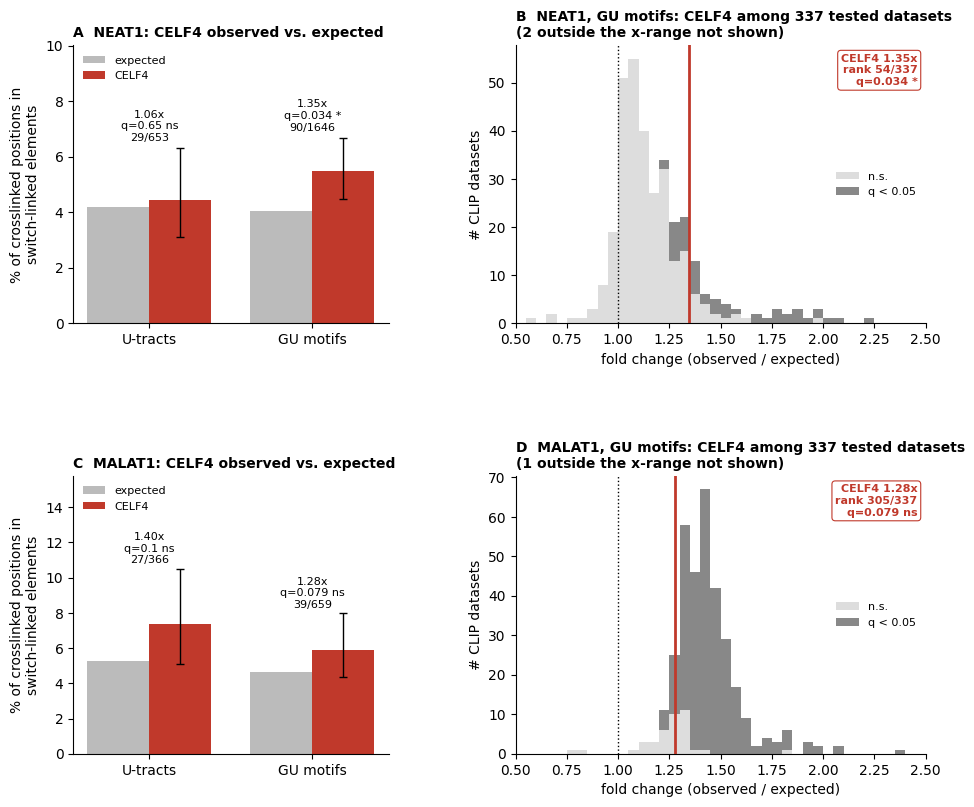

,gene,element,n_crosslinks_in_elements,n_in_switch_elements,observed_rate,expected_rate,fold_change,p_value,q_value_bh,rank_fc
304,MALAT1,GU motifs,659,39,0.059181,0.046341,1.277055,0.073954,0.079371,305.0
448,MALAT1,U-tracts,366,27,0.073770,0.052838,1.396175,0.052465,0.103228,111.0
729,NEAT1,GU motifs,1646,90,0.054678,0.040553,1.348324,0.003214,0.033852,54.0
1227,NEAT1,U-tracts,653,29,0.044410,0.041938,1.058942,0.402901,0.647725,214.0
1465,NORAD,GU motifs,428,38,0.088785,0.085766,1.035196,0.436409,1.000000,114.0
1880,NORAD,U-tracts,149,2,0.013423,0.044872,0.299137,0.991444,1.000000,191.0
2140,TUG1,GU motifs,170,16,0.094118,0.127013,0.741011,0.924632,1.000000,113.0
2513,TUG1,U-tracts,74,5,0.067568,0.125589,0.538007,0.963569,1.000000,148.0
2767,XIST,GU motifs,1878,45,0.023962,0.023067,1.038770,0.418821,1.000000,64.0
3083,XIST,U-tracts,811,3,0.003699,0.003284,1.126387,0.497633,1.000000,42.0


In [11]:
CELF4_DATASET = "all-Celf4-FlpIn293_iCLIP"
CELF4_COLOR, EXPECTED_COLOR = "#c0392b", "#bbbbbb"
FC_RANGE = (0.5, 2.5)   # x-range of the distribution panels; datasets outside are counted in the title
CELF4_GENES = ["NEAT1", "MALAT1"]


def wilson_ci(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


fig, axes = plt.subplots(len(CELF4_GENES), 2, figsize=(11, 4.6 * len(CELF4_GENES)),
                         gridspec_kw={"width_ratios": [1, 1.3], "wspace": 0.35, "hspace": 0.55})
for row, gene in enumerate(CELF4_GENES):
    # left: observed vs. expected, this lncRNA only
    ax = axes[row, 0]
    celf4 = clip[(clip["dataset"] == CELF4_DATASET) & (clip["gene"] == gene)].set_index("element").reindex(elements)
    x = np.arange(len(elements))
    w = 0.38
    lo, hi = wilson_ci(celf4["n_in_switch_elements"].values, celf4["n_crosslinks_in_elements"].values)
    obs = celf4["observed_rate"].values
    ax.bar(x - w / 2, 100 * celf4["expected_rate"], w, color=EXPECTED_COLOR, label="expected")
    ax.bar(x + w / 2, 100 * obs, w, color=CELF4_COLOR, label="CELF4",
           yerr=100 * np.vstack([obs - lo, hi - obs]), capsize=3, error_kw={"elinewidth": 1})
    for xi, r, h in zip(x, celf4.itertuples(), 100 * hi):
        ax.text(xi, h + 0.2, f"{r.observed_rate / r.expected_rate:.2f}x\nq={r.q_value_bh:.2g} {stars(r.q_value_bh)}\n"
                f"{r.n_in_switch_elements}/{r.n_crosslinks_in_elements}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(elements)
    ax.set_ylabel("% of crosslinked positions in\nswitch-linked elements")
    ax.set_ylim(0, 100 * hi.max() * 1.5)
    ax.legend(fontsize=8, loc="upper left", frameon=False)
    ax.set_title(f"{'AC'[row]}  {gene}: CELF4 observed vs. expected", loc="left", weight="bold", fontsize=10)
    sns.despine(ax=ax)

    # right: CELF4 among all tested datasets, GU motifs
    ax = axes[row, 1]
    d = clip[(clip["gene"] == gene) & (clip["element"] == "GU motifs")]
    fc = d["observed_rate"] / d["expected_rate"]
    sig = d["q_value_bh"] < 0.05
    inside = fc.between(*FC_RANGE)
    bins = np.linspace(*FC_RANGE, 41)
    ax.hist([fc[~sig & inside], fc[sig & inside]], bins=bins, stacked=True, color=["#dddddd", "#888888"],
            label=["n.s.", "q < 0.05"])
    c = d[d["dataset"] == CELF4_DATASET].iloc[0]
    c_fc = c["observed_rate"] / c["expected_rate"]
    ax.axvline(c_fc, color=CELF4_COLOR, lw=2, zorder=5)
    ax.axvline(1, color="black", linestyle=":", lw=1)
    ax.text(0.98, 0.97, f"CELF4 {c_fc:.2f}x\nrank {int(c['rank_fc'])}/{len(d)}\n"
            f"q={c['q_value_bh']:.2g} {stars(c['q_value_bh'])}", transform=ax.transAxes, ha="right", va="top",
            color=CELF4_COLOR, fontsize=8, weight="bold",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=CELF4_COLOR, lw=0.8))
    ax.set_xlim(*FC_RANGE)
    ax.set_xlabel("fold change (observed / expected)")
    ax.set_ylabel("# CLIP datasets")
    n_out = int((~inside).sum())
    ax.set_title(f"{'BD'[row]}  {gene}, GU motifs: CELF4 among {len(d)} tested datasets"
                 + (f"\n({n_out} outside the x-range not shown)" if n_out else ""), loc="left", weight="bold", fontsize=10)
    ax.legend(fontsize=8, loc="center right", frameon=False)
    sns.despine(ax=ax)

# plt.savefig(f"{figures_subfolder}/CELF4_switch_preference.pdf", bbox_inches="tight")
plt.show()
(clip[clip["dataset"] == CELF4_DATASET][["gene", "element", "n_crosslinks_in_elements", "n_in_switch_elements",
                                         "observed_rate", "expected_rate", "fold_change", "p_value",
                                         "q_value_bh", "rank_fc"]])

## 5. Summary figures

**m6A density per lncRNA -- lncRNAs differ in m6A density.** RMBase m6A sites per kb of mature RNA; the dark part of each bar is the
switch-competent sites (U-rich or UG-rich). lncRNAs ordered by m6A density (same order in the CELF4 plot). Saved: `barplot_m6A_density_per_lncRNA.pdf`.

**CELF4 preference per lncRNA -- CELF4 prefers m6A-switch-linked GU motifs on NEAT1 only.** CELF4 iCLIP: fold change (observed / expected
share of crosslinked positions in switch-linked GU motifs), 95% Wilson CI; dotted line = no preference; q = BH over
the tested datasets of that lncRNA. (U-tracts: no significant preference on any lncRNA, see section 4.) Saved: `barplot_CELF4_preference_switch_GU_motifs_per_lncRNA.pdf`.

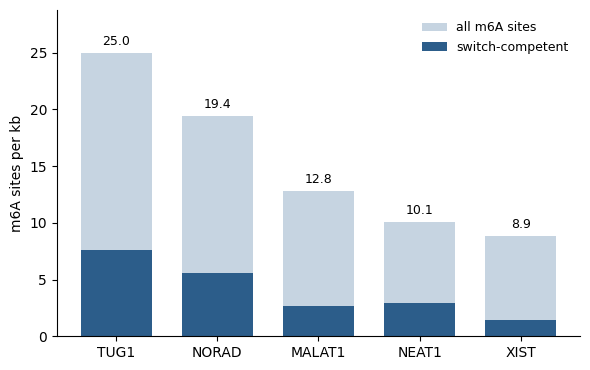

,length,n_sites_on_A,m6a_per_kb,competent_per_kb
gene,,,,
TUG1,7474,187,25.0,7.6
NORAD,5401,105,19.4,5.6
MALAT1,10434,134,12.8,2.7
NEAT1,22743,230,10.1,2.9
XIST,19245,171,8.9,1.4


In [12]:
# m6A density per lncRNA
dens = genes_df.copy()
n_competent = sites.assign(comp=sites["u_rich"] | sites["ug_rich"]).groupby("gene")["comp"].sum()
dens["m6a_per_kb"] = 1000 * dens["n_sites_on_A"] / dens["length"]
dens["competent_per_kb"] = 1000 * n_competent.reindex(dens.index).fillna(0) / dens["length"]
dens = dens.sort_values("m6a_per_kb", ascending=False)
lnc_order = dens.index.tolist()   # reused in the CELF4 plot

fig, ax = plt.subplots(figsize=(6, 3.8))
x = np.arange(len(dens))
ax.bar(x, dens["m6a_per_kb"], color="#c6d4e1", width=0.7, label="all m6A sites")
ax.bar(x, dens["competent_per_kb"], color="#2c5d8a", width=0.7, label="switch-competent")
for xi, r in zip(x, dens.itertuples()):
    ax.text(xi, r.m6a_per_kb + 0.4, f"{r.m6a_per_kb:.1f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(dens.index, fontsize=10)
ax.set_ylabel("m6A sites per kb")
ax.set_ylim(0, dens["m6a_per_kb"].max() * 1.15)
ax.legend(frameon=False, fontsize=9)
sns.despine(ax=ax)
plt.tight_layout()
save_figure(f"{figures_subfolder}/barplot_m6A_density_per_lncRNA.pdf",
            legend="RMBase m6A sites per kb of mature transcript for each lncRNA (light), with the switch-competent "
                   "sites (partner U in a U-tract or a UG 3-mer, p(i,j) >= 0.5) in dark; lncRNAs ordered by m6A density.")
plt.show()
dens[["length", "n_sites_on_A", "m6a_per_kb", "competent_per_kb"]].round(1)

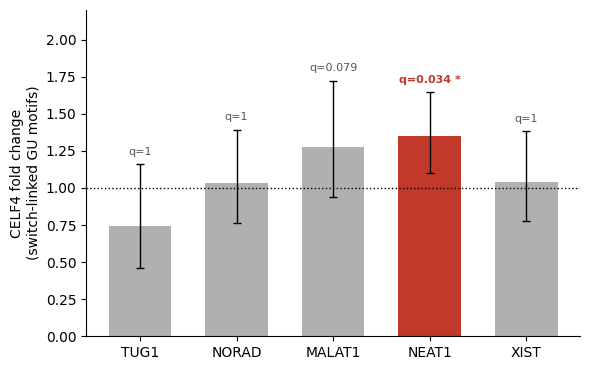

In [13]:
# CELF4 preference for switch-linked GU motifs, per lncRNA
c4 = (clip_all[(clip_all["dataset"] == CELF4_DATASET) & (clip_all["element"] == "GU motifs")]
      .set_index("gene").reindex(lnc_order))
fig, ax = plt.subplots(figsize=(6, 3.8))
x = np.arange(len(c4))
for xi, (gene, r) in zip(x, c4.iterrows()):
    if not r["tested"]:
        ax.text(xi, 1.05, "not\ntestable", ha="center", va="bottom", fontsize=8, color="#888888")
        continue
    lo, hi = wilson_ci(r["n_in_switch_elements"], r["n_crosslinks_in_elements"])
    fc, e = r["observed_rate"] / r["expected_rate"], r["expected_rate"]
    sig = r["q_value_bh"] < 0.05
    color = CELF4_COLOR if sig else "#b0b0b0"
    ax.bar(xi, fc, width=0.65, color=color)
    ax.errorbar(xi, fc, yerr=[[fc - lo / e], [hi / e - fc]], color="black", capsize=3, lw=1)
    ax.text(xi, hi / e + 0.05, f"q={r['q_value_bh']:.2g}" + (" *" if sig else ""), ha="center", va="bottom",
            fontsize=8, color=CELF4_COLOR if sig else "#555555", weight="bold" if sig else "normal")
ax.axhline(1, color="black", linestyle=":", lw=1)
ax.set_xticks(x)
ax.set_xticklabels(c4.index, fontsize=10)
ax.set_ylabel("CELF4 fold change\n(switch-linked GU motifs)")
ax.set_ylim(0, 2.2)
sns.despine(ax=ax)
plt.tight_layout()
save_figure(f"{figures_subfolder}/barplot_CELF4_preference_switch_GU_motifs_per_lncRNA.pdf",
            legend="CELF4 iCLIP (all-Celf4-FlpIn293): fold change of the share of crosslinked positions in "
                   "m6A-switch-linked GU motifs (observed / expected) per lncRNA. Error bars: 95% Wilson score CI on k/n (k = CELF4 "
                   "crosslinked positions in switch-linked GU "
                   "motifs, n = all CELF4 crosslinked positions in GU motifs of that lncRNA), divided by the expected "
                   "share; counting (binomial sampling) uncertainty only, no replicates, narrows as n grows. Red = q < 0.05 "
                   "(one-sided binomial, BH over the tested datasets of that lncRNA), grey = n.s.; 'not testable' = fewer "
                   "than 20 crosslinked positions. Dotted line = no preference.")
plt.show()

**Preference of all CLIP datasets for m6A-switch-linked GU motifs, per lncRNA.** For each lncRNA, the distribution
over all tested CLIP datasets (>= 20 crosslinked positions in GU motifs of that lncRNA; one value per dataset, so
replicates / cell lines of an RBP count separately) of the fold change (observed / expected share of crosslinked positions
in switch-linked GU motifs) and of -log10(p) (one-sided binomial test, uncorrected). lncRNAs in the m6A-density order
above; lncRNAs without a tested dataset are left out. Saved: `boxplot_all_RBPs_fold_change_switch_GU_motifs_per_lncRNA.pdf`,
`boxplot_all_RBPs_neglog10p_switch_GU_motifs_per_lncRNA.pdf`.

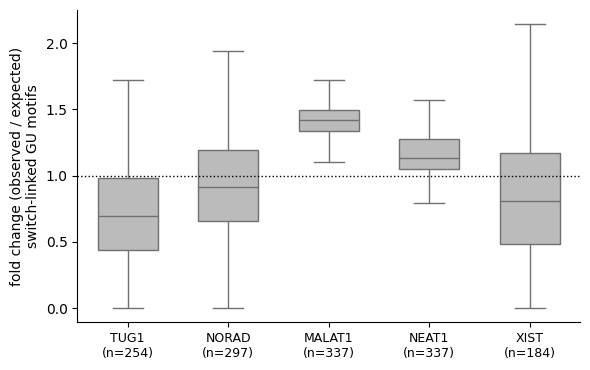

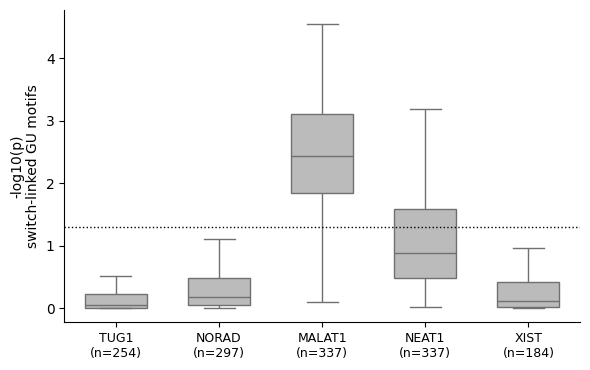

,fold_change,neg_log10_p,n_tested
gene,,,
TUG1,0.69,0.06,254
NORAD,0.92,0.17,297
MALAT1,1.42,2.44,337
NEAT1,1.13,0.88,337
XIST,0.81,0.12,184


In [14]:
# Distribution over all tested CLIP datasets, per lncRNA: GU motifs only
gu = clip[clip["element"] == "GU motifs"].copy()
gu["neg_log10_p"] = -np.log10(gu["p_value"].clip(lower=P_FLOOR))
gu_order = [g for g in lnc_order if (gu["gene"] == g).any()]
n_tested = gu.groupby("gene").size().reindex(gu_order)
xticklabels = [f"{g}\n(n={n})" for g, n in n_tested.items()]

LEGEND_COMMON = ("one box per lncRNA (ordered by m6A density), over all CLIP datasets tested on it (>= 20 crosslinked "
                 "positions in its GU motifs; one value per dataset, replicates / cell lines of an RBP counted "
                 "separately; n under each name). Boxes = median and IQR, whiskers 1.5 x IQR, outliers not shown.")

for col, ylabel, ref, fname, what in [
        ("fold_change", "fold change (observed / expected)\nswitch-linked GU motifs", 1,
         "boxplot_all_RBPs_fold_change_switch_GU_motifs_per_lncRNA.pdf",
         "Fold change of the share of crosslinked positions in m6A-switch-linked GU motifs (observed / expected; dotted "
         "line = 1, no preference)"),
        ("neg_log10_p", "-log10(p)\nswitch-linked GU motifs", -np.log10(0.05),
         "boxplot_all_RBPs_neglog10p_switch_GU_motifs_per_lncRNA.pdf",
         "-log10(p) of the preference for m6A-switch-linked GU motifs (one-sided binomial test on crosslinked positions, "
         "uncorrected p; dotted line = p 0.05)")]:
    fig, ax = plt.subplots(figsize=(6, 3.8))
    sns.boxplot(data=gu, x="gene", y=col, order=gu_order, color="#bbbbbb", showfliers=False, width=0.6, ax=ax)
    ax.axhline(ref, color="black", linestyle=":", lw=1)
    ax.set_xticks(range(len(gu_order)))
    ax.set_xticklabels(xticklabels, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    sns.despine(ax=ax)
    plt.tight_layout()
    save_figure(f"{figures_subfolder}/{fname}", legend=f"{what}: {LEGEND_COMMON}")
    plt.show()

gu.groupby("gene")[["fold_change", "neg_log10_p"]].median().reindex(gu_order).assign(n_tested=n_tested).round(2)

**Same, with the regulators of lengthening.** Grey = all tested datasets (as above, regulators included); next to it,
the tested datasets of the R1 (`#51be93`), R2 (`#d41c5c`) and R3 (`#fbb040`) regulators of lengthening
(`../Tables/Figure_regulators_lengthening/regulators_of_nuclear_3UTR_lengthening_D22_to_D35_CTRL_<region>_APA_vs_nuclear_retention_class.csv` (`<region>` = `region1_upstream_pPAS`, `region2_downstream_pPAS` or `region3_upstream_dPAS`), matched to the CLIP datasets as in section 3). p above each regulator box: two-sided Mann-Whitney, the region's regulators vs the other datasets tested on that lncRNA, uncorrected (computed here; BH q over the 15 lncRNA x region tests of each figure in the printed table).
Saved: `boxplot_all_RBPs_vs_R1_R2_R3_regulators_fold_change_switch_GU_motifs_per_lncRNA.pdf`,
`boxplot_all_RBPs_vs_R1_R2_R3_regulators_neglog10p_switch_GU_motifs_per_lncRNA.pdf`.

R1: 11 regulators matched to CLIP datasets
R2: 17 regulators matched to CLIP datasets
R3: 15 regulators matched to CLIP datasets


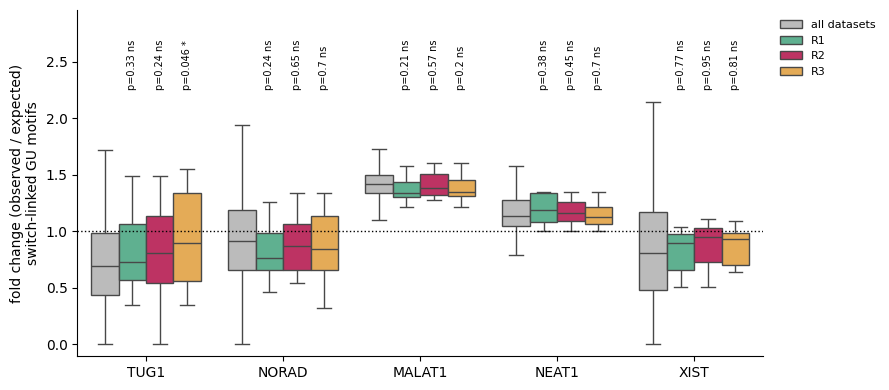

,gene,group,n_regulators,n_rest,median_regulators,median_rest,p_value,q_value_bh
0,TUG1,R1,10,244,0.728,0.690,0.330,0.805
1,TUG1,R2,17,237,0.808,0.689,0.240,0.724
2,TUG1,R3,15,239,0.895,0.688,0.046,0.697
3,NORAD,R1,11,286,0.763,0.919,0.241,0.724
4,NORAD,R2,17,280,0.870,0.919,0.654,0.865
5,NORAD,R3,15,282,0.839,0.919,0.702,0.865
6,MALAT1,R1,11,326,1.337,1.419,0.205,0.724
7,MALAT1,R2,17,320,1.384,1.419,0.571,0.865
8,MALAT1,R3,15,322,1.347,1.419,0.200,0.724
9,NEAT1,R1,11,326,1.186,1.125,0.376,0.805


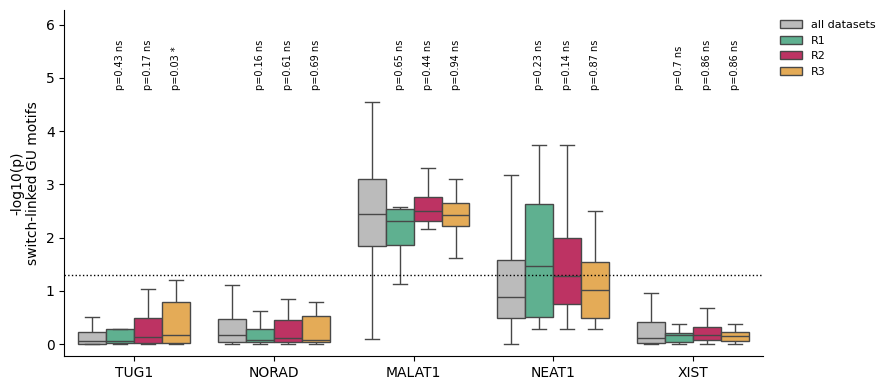

,gene,group,n_regulators,n_rest,median_regulators,median_rest,p_value,q_value_bh
0,TUG1,R1,10,244,0.058,0.056,0.429,0.930
1,TUG1,R2,17,237,0.127,0.053,0.175,0.655
2,TUG1,R3,15,239,0.172,0.052,0.030,0.452
3,NORAD,R1,11,286,0.085,0.177,0.161,0.655
4,NORAD,R2,17,280,0.112,0.176,0.611,0.930
5,NORAD,R3,15,282,0.086,0.176,0.687,0.930
6,MALAT1,R1,11,326,2.322,2.442,0.654,0.930
7,MALAT1,R2,17,320,2.509,2.425,0.442,0.930
8,MALAT1,R3,15,322,2.423,2.442,0.942,0.942
9,NEAT1,R1,11,326,1.465,0.878,0.234,0.703


group,all datasets,R1,R2,R3
gene,,,,
TUG1,254,10,17,15
NORAD,297,11,17,15
MALAT1,337,11,17,15
NEAT1,337,11,17,15
XIST,184,10,14,12


In [15]:
# Same distributions, with the R1, R2 and R3 regulators of lengthening next to all datasets
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

REG_COLORS = {"R1": "#51be93", "R2": "#d41c5c", "R3": "#fbb040"}
GROUP_COLORS = {"all datasets": "#bbbbbb", **REG_COLORS}
reg_datasets = {}
for k in (1, 2, 3):
    c = pd.read_csv(figures.lengthening_regulators_csv(k), index_col=0)
    reg_datasets[f"R{k}"] = {dataset_of_path[resolve_clip_file(r)] for r in c["regulator"]}
    print(f"R{k}: {len(reg_datasets[f'R{k}'])} regulators matched to CLIP datasets")

# one row per (dataset, group): every dataset in "all datasets", regulators again in their region(s)
gu_groups = pd.concat([gu.assign(group="all datasets")] +
                      [gu[gu["dataset"].isin(ds)].assign(group=r) for r, ds in reg_datasets.items()],
                      ignore_index=True)
n_group = gu_groups.groupby(["gene", "group"]).size().unstack().reindex(index=gu_order, columns=list(GROUP_COLORS))

LEGEND_REG = ("one group of boxes per lncRNA (ordered by m6A density): all CLIP datasets tested on it (grey; >= 20 "
              "crosslinked positions in its GU motifs; one value per dataset, replicates / cell lines of an RBP counted "
              "separately; regulators included) and, among them, the R1 (green), R2 (red) and R3 (orange) regulators of "
              "lengthening (Figure_regulators_lengthening.ipynb). Boxes = median and IQR, whiskers 1.5 x IQR, "
              "outliers not shown. p (above each regulator box) = two-sided Mann-Whitney test, the region's regulators vs the "
              "other datasets tested on that lncRNA, uncorrected (* p < 0.05, ** p < 0.01, *** p < 1e-4).")

for col, ylabel, ref, fname, what in [
        ("fold_change", "fold change (observed / expected)\nswitch-linked GU motifs", 1,
         "boxplot_all_RBPs_vs_R1_R2_R3_regulators_fold_change_switch_GU_motifs_per_lncRNA.pdf",
         "Fold change of the share of crosslinked positions in m6A-switch-linked GU motifs (observed / expected; dotted "
         "line = 1, no preference)"),
        ("neg_log10_p", "-log10(p)\nswitch-linked GU motifs", -np.log10(0.05),
         "boxplot_all_RBPs_vs_R1_R2_R3_regulators_neglog10p_switch_GU_motifs_per_lncRNA.pdf",
         "-log10(p) of the preference for m6A-switch-linked GU motifs (one-sided binomial test on crosslinked positions, "
         "uncorrected p; dotted line = p 0.05)")]:
    # two-sided Mann-Whitney: regulators of the region vs the other datasets on that lncRNA (raw p on the plot,
    # BH q over the 15 lncRNA x region tests in the table only)
    tests = []
    for gene in gu_order:
        g = gu[gu["gene"] == gene]
        for r, ds in reg_datasets.items():
            reg, rest = g[g["dataset"].isin(ds)][col], g[~g["dataset"].isin(ds)][col]
            tests.append({"gene": gene, "group": r, "n_regulators": len(reg), "n_rest": len(rest),
                          "median_regulators": reg.median(), "median_rest": rest.median(),
                          "p_value": mannwhitneyu(reg, rest, alternative="two-sided").pvalue})
    tests = pd.DataFrame(tests)
    tests["q_value_bh"] = multipletests(tests["p_value"], method="fdr_bh")[1]

    fig, ax = plt.subplots(figsize=(9, 4))
    sns.boxplot(data=gu_groups, x="gene", y=col, hue="group", order=gu_order, hue_order=list(GROUP_COLORS),
                palette=GROUP_COLORS, showfliers=False, width=0.8, ax=ax)
    ax.axhline(ref, color="black", linestyle=":", lw=1)
    y0, y1 = ax.get_ylim()
    offsets = dict(zip(GROUP_COLORS, np.linspace(-0.3, 0.3, len(GROUP_COLORS))))   # hue positions (width 0.8)
    for t in tests.itertuples():
        ax.text(gu_order.index(t.gene) + offsets[t.group], y1, f"p={t.p_value:.2g} {stars(t.p_value)}",
                rotation=90, ha="center", va="bottom", fontsize=7)
    ax.set_ylim(y0, y1 + 0.3 * (y1 - y0))
    ax.set_xticks(range(len(gu_order)))
    ax.set_xticklabels(gu_order, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.legend(title="", frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    sns.despine(ax=ax)
    plt.tight_layout()
    save_figure(f"{figures_subfolder}/{fname}", legend=f"{what}: {LEGEND_REG}")
    plt.show()
    display(tests.round(3))

# number of tested datasets per lncRNA and group
n_group

**Same, R2 regulators split by category.** Grey = all tested datasets (regulators included); next to it, the R2
regulators of lengthening (`../Tables/Figure_regulators_lengthening/regulators_of_nuclear_3UTR_lengthening_D22_to_D35_CTRL_region2_downstream_pPAS_APA_vs_nuclear_retention_class.csv`) split into APA (pink) and nuclear retention
(NR, green) regulators. p = two-sided Mann-Whitney test, the group vs the other datasets tested on that lncRNA
(uncorrected on the plot; BH q over the 10 lncRNA x group tests in the table).

{'R2 APA': 6, 'R2 NR': 11} R2 regulators matched to CLIP datasets


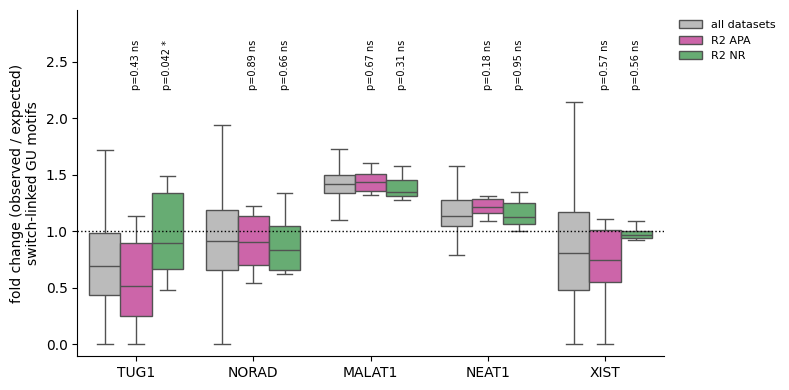

,gene,group,n_regulators,n_rest,median_regulators,median_rest,p_value,q_value_bh
0,TUG1,R2 APA,6,248,0.514,0.692,0.433,0.835
1,TUG1,R2 NR,11,243,0.895,0.688,0.042,0.425
2,NORAD,R2 APA,6,291,0.904,0.916,0.887,0.949
3,NORAD,R2 NR,11,286,0.833,0.919,0.657,0.835
4,MALAT1,R2 APA,6,331,1.434,1.418,0.668,0.835
5,MALAT1,R2 NR,11,326,1.347,1.419,0.309,0.835
6,NEAT1,R2 APA,6,331,1.212,1.127,0.184,0.835
7,NEAT1,R2 NR,11,326,1.127,1.131,0.949,0.949
8,XIST,R2 APA,6,178,0.742,0.809,0.569,0.835
9,XIST,R2 NR,8,176,0.964,0.801,0.557,0.835


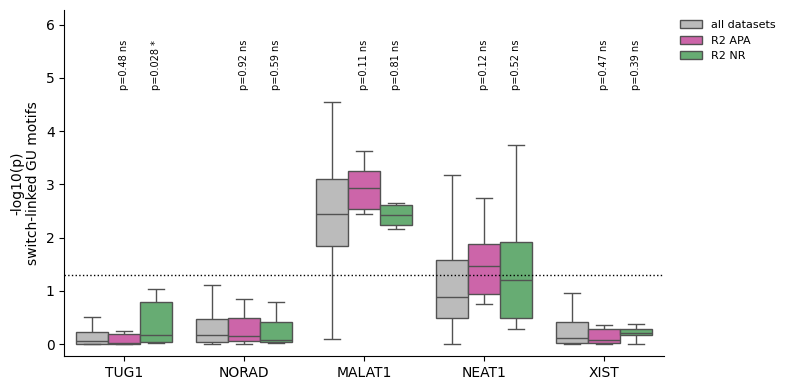

,gene,group,n_regulators,n_rest,median_regulators,median_rest,p_value,q_value_bh
0,TUG1,R2 APA,6,248,0.024,0.058,0.484,0.732
1,TUG1,R2 NR,11,243,0.172,0.052,0.028,0.285
2,NORAD,R2 APA,6,291,0.154,0.174,0.916,0.916
3,NORAD,R2 NR,11,286,0.086,0.176,0.585,0.732
4,MALAT1,R2 APA,6,331,2.942,2.425,0.110,0.404
5,MALAT1,R2 NR,11,326,2.423,2.442,0.810,0.900
6,NEAT1,R2 APA,6,331,1.467,0.879,0.121,0.404
7,NEAT1,R2 NR,11,326,1.200,0.878,0.520,0.732
8,XIST,R2 APA,6,178,0.086,0.124,0.471,0.732
9,XIST,R2 NR,8,176,0.203,0.113,0.390,0.732


group,all datasets,R2 APA,R2 NR
gene,,,
TUG1,254,6,11
NORAD,297,6,11
MALAT1,337,6,11
NEAT1,337,6,11
XIST,184,6,8


In [16]:
# Same distributions, with the R2 regulators of lengthening split into APA and nuclear-retention (NR) regulators
R2_CAT_COLORS = {"R2 APA": "#dd54af", "R2 NR": "#5cb76b"}
GROUP_COLORS_R2 = {"all datasets": "#bbbbbb", **R2_CAT_COLORS}
c2 = pd.read_csv(figures.lengthening_regulators_csv(2), index_col=0)
c2["dataset"] = [dataset_of_path[resolve_clip_file(r)] for r in c2["regulator"]]
r2_datasets = {"R2 APA": set(c2.loc[c2["category"] == "APA", "dataset"]),
               "R2 NR": set(c2.loc[c2["category"] == "Nuclear retention", "dataset"])}
print({k: len(v) for k, v in r2_datasets.items()}, "R2 regulators matched to CLIP datasets")

gu_groups_r2 = pd.concat([gu.assign(group="all datasets")] +
                         [gu[gu["dataset"].isin(ds)].assign(group=r) for r, ds in r2_datasets.items()],
                         ignore_index=True)
n_group_r2 = gu_groups_r2.groupby(["gene", "group"]).size().unstack().reindex(index=gu_order, columns=list(GROUP_COLORS_R2))

LEGEND_R2 = ("one group of boxes per lncRNA (ordered by m6A density): all CLIP datasets tested on it (grey; >= 20 "
             "crosslinked positions in its GU motifs; one value per dataset, replicates / cell lines of an RBP counted "
             "separately; regulators included) and, among them, the R2 regulators of lengthening "
             "(Figure_regulators_lengthening.ipynb) split into APA (pink) and nuclear-retention (NR, green) "
             "regulators. Boxes = median and IQR, whiskers 1.5 x IQR, outliers not shown. p (above each regulator box) = "
             "two-sided Mann-Whitney test, the group vs the other datasets tested on that lncRNA, uncorrected "
             "(* p < 0.05, ** p < 0.01, *** p < 1e-4).")

for col, ylabel, ref, fname, what in [
        ("fold_change", "fold change (observed / expected)\nswitch-linked GU motifs", 1,
         "boxplot_all_RBPs_vs_R2_APA_NR_regulators_fold_change_switch_GU_motifs_per_lncRNA.pdf",
         "Fold change of the share of crosslinked positions in m6A-switch-linked GU motifs (observed / expected; dotted "
         "line = 1, no preference)"),
        ("neg_log10_p", "-log10(p)\nswitch-linked GU motifs", -np.log10(0.05),
         "boxplot_all_RBPs_vs_R2_APA_NR_regulators_neglog10p_switch_GU_motifs_per_lncRNA.pdf",
         "-log10(p) of the preference for m6A-switch-linked GU motifs (one-sided binomial test on crosslinked positions, "
         "uncorrected p; dotted line = p 0.05)")]:
    tests = []
    for gene in gu_order:
        g = gu[gu["gene"] == gene]
        for r, ds in r2_datasets.items():
            reg, rest = g[g["dataset"].isin(ds)][col], g[~g["dataset"].isin(ds)][col]
            p = mannwhitneyu(reg, rest, alternative="two-sided").pvalue if len(reg) else np.nan
            tests.append({"gene": gene, "group": r, "n_regulators": len(reg), "n_rest": len(rest),
                          "median_regulators": reg.median(), "median_rest": rest.median(), "p_value": p})
    tests = pd.DataFrame(tests)
    ok = tests["p_value"].notna()
    tests.loc[ok, "q_value_bh"] = multipletests(tests.loc[ok, "p_value"], method="fdr_bh")[1]

    fig, ax = plt.subplots(figsize=(8, 4))
    sns.boxplot(data=gu_groups_r2, x="gene", y=col, hue="group", order=gu_order, hue_order=list(GROUP_COLORS_R2),
                palette=GROUP_COLORS_R2, showfliers=False, width=0.8, ax=ax)
    ax.axhline(ref, color="black", linestyle=":", lw=1)
    y0, y1 = ax.get_ylim()
    offsets = dict(zip(GROUP_COLORS_R2, np.linspace(-0.8 / 3, 0.8 / 3, len(GROUP_COLORS_R2))))   # hue positions
    for t in tests[ok].itertuples():
        ax.text(gu_order.index(t.gene) + offsets[t.group], y1, f"p={t.p_value:.2g} {stars(t.p_value)}",
                rotation=90, ha="center", va="bottom", fontsize=7)
    ax.set_ylim(y0, y1 + 0.3 * (y1 - y0))
    ax.set_xticks(range(len(gu_order)))
    ax.set_xticklabels(gu_order, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.legend(title="", frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    sns.despine(ax=ax)
    plt.tight_layout()
    save_figure(f"{figures_subfolder}/{fname}", legend=f"{what}: {LEGEND_R2}")
    plt.show()
    display(tests.round(3))

# number of tested datasets per lncRNA and group
n_group_r2